In [1]:
from astropy.io import fits
from spectral_cube import SpectralCube
import astropy.units as u
import numpy as np
import matplotlib.pyplot as plt
from astropy.wcs import WCS


In [2]:
name_fits_file = 'observations/cube_30dor_Halpha_WCS.fits'   

In [3]:
hdul_cube = fits.open(name_fits_file)
hdul_cube.info()
data_cube = hdul_cube[0].data.astype(float)

hdul_cube.close()

Filename: observations/cube_30dor_Halpha_WCS.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      71   (32, 30, 220)   float32   


In [4]:
with fits.open(name_fits_file) as hdul:
    header = hdul[0].header.copy()
    data_cube = hdul[0].data.astype(float)

print("Data shape:", data_cube.shape)

# Inspect coordinate information
for i in range(1, 4):
    print(f"\nAXIS {i}")
    for key in ["CTYPE", "CUNIT", "CRVAL", "CRPIX", "CDELT"]:
        keyword = f"{key}{i}"
        print(f"{keyword}: {header.get(keyword, 'NOT FOUND')}")

# Inspect Astropy's interpretation
wcs = WCS(header)

print("\nWCS axis types:")
print(wcs.get_axis_types())

print("\nWCS:")
print(wcs)

Data shape: (220, 30, 32)

AXIS 1
CTYPE1: RA---TAN
CUNIT1: NOT FOUND
CRVAL1: 84.7217102051
CRPIX1: 14.0
CDELT1: NOT FOUND

AXIS 2
CTYPE2: DEC--TAN
CUNIT2: NOT FOUND
CRVAL2: -69.1499786377
CRPIX2: 6.0
CDELT2: NOT FOUND

AXIS 3
CTYPE3: NOT FOUND
CUNIT3: NOT FOUND
CRVAL3: 656.35
CRPIX3: 1.0
CDELT3: 0.005

WCS axis types:
[{'coordinate_type': 'celestial', 'scale': 'non-linear celestial', 'group': 0, 'number': 0}, {'coordinate_type': 'celestial', 'scale': 'non-linear celestial', 'group': 0, 'number': 1}, {'coordinate_type': None, 'scale': 'linear', 'group': 0, 'number': 0}]

WCS:
WCS Keywords

Number of WCS axes: 3
CTYPE : 'RA---TAN' 'DEC--TAN' '' 
CRVAL : 84.7217102051 -69.1499786377 656.35 
CRPIX : 14.0 6.0 1.0 
CD1_1 CD1_2 CD1_3  : -0.00557723991055 1.95156391047e-17 0.0 
CD2_1 CD2_2 CD2_3  : 1.90819582357e-17 0.00555253180951 0.0 
CD3_1 CD3_2 CD3_3  : 0.0 0.0 1.0 
NAXIS : 32  30  220


In [5]:
# Inspect spatial coordinate transformation keywords
for key in header:
    if key.startswith(("CD", "PC", "CROTA")):
        print(f"{key}: {header[key]}")

CDELT3: 0.005
CD1_1: -0.00557723991055
CD2_1: 1.90819582357e-17
CD1_2: 1.95156391047e-17
CD2_2: 0.00555253180951


In [6]:
# Check the original FITS header
print("CD3_3 in original header:", header.get("CD3_3"))
print("CDELT3 in original header:", header.get("CDELT3"))

# Select three spectral channels
pixels = np.array([
    [13, 5, 0],
    [13, 5, 1],
    [13, 5, 219]
])

# Convert pixel coordinates to WCS coordinates
world = wcs.all_pix2world(pixels, 0)

print("\nSpectral coordinates calculated by WCS:")
print(world[:, 2])

CD3_3 in original header: None
CDELT3 in original header: 0.005

Spectral coordinates calculated by WCS:
[656.35 657.35 875.35]


In [7]:
print(header)

SIMPLE  =                    T / Written by IDL:  Fri Jul 27 12:11:26 2012      BITPIX  =                  -32 / Bits per pixel                                 NAXIS   =                    3 / Number of axes                                 NAXIS1  =                   32 /Number of positions along axis 1                NAXIS2  =                   30 /Number of positions along axis 2                NAXIS3  =                  220 /Number of positions along axis 3                EXTEND  =                    T / File may contain extensions                    ORIGIN  = 'NOAO-IRAF FITS Image Kernel July 2003' / FITS file originator        IRAF-TLM= '2012-07-27T16:00:04' / Time of last modification                     DATE    = '2012-07-27T15:41:10' / Creation UTC (CCCC-MM-DD) date of FITS header COMMENT FITS (Flexible Image Transport System) format is defined in 'Astronomy  COMMENT and Astrophysics', volume 376, page 359; bibcode 2001A&A...376..359H    CRPIX3  =              1.00000 /        

In [8]:

# ============================================================
# 1. CORRECT THE HEADER
# ============================================================

header_fixed = header.copy()

# Provisional: assume air wavelengths in nanometers
# Use "WAVE" instead if the calibration is in vacuum.
header_fixed["CTYPE3"] = "AWAV"
header_fixed["CUNIT3"] = "nm"

# Incorporate spectral increment into the CD matrix
header_fixed["CD3_3"] = header_fixed["CDELT3"]

# Remove the conflicting keyword
del header_fixed["CDELT3"]

# ============================================================
# 2. CONSTRUCT WCS
# ============================================================

wcs_fixed = WCS(header_fixed)

print("WCS axis types:")
print(wcs_fixed.get_axis_types())

# ============================================================
# 3. CONSTRUCT SPECTRAL CUBE
# ============================================================

cube = SpectralCube(
    data=data_cube,
    wcs=wcs_fixed
)

print("\nSpectralCube:")
print(cube)

# ============================================================
# 4. VERIFY SPECTRAL COORDINATES
# ============================================================

wavelength = cube.spectral_axis.to(u.nm)

print("\nSpectral axis [nm]:")
print(wavelength[[0, 1, -1]])

print("\nSpectral increment:")
print(wavelength[1] - wavelength[0])

WCS axis types:
[{'coordinate_type': 'celestial', 'scale': 'non-linear celestial', 'group': 0, 'number': 0}, {'coordinate_type': 'celestial', 'scale': 'non-linear celestial', 'group': 0, 'number': 1}, {'coordinate_type': 'spectral', 'scale': 'linear', 'group': 0, 'number': 0}]

SpectralCube:
SpectralCube with shape=(220, 30, 32):
 n_x:     32  type_x: RA---TAN  unit_x: deg    range:    84.439297 deg:   84.925676 deg
 n_y:     30  type_y: DEC--TAN  unit_y: deg    range:   -69.177621 deg:  -69.016489 deg
 n_s:    220  type_s: AWAV      unit_s: m      range:        0.000 m:       0.000 m

Spectral axis [nm]:
[656.35  656.355 657.445] nm

Spectral increment:
0.0049999999999954525 nm


Spectral channels: 220
Spatial dimensions: 30 x 32
Valid spatial pixels: 960 / 960
Selected spatial pixel: x=15, y=16


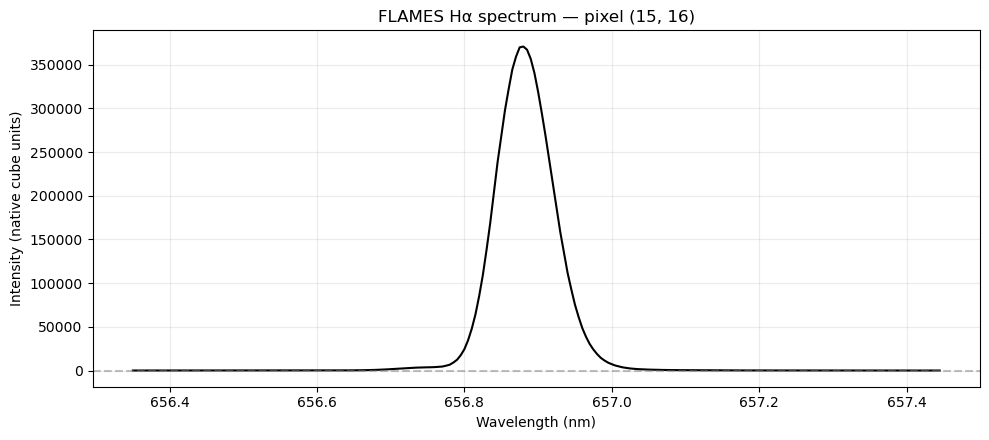

In [9]:
# ============================================================
# 1. SPECTRAL AXIS
# ============================================================

wavelength = cube.spectral_axis.to(u.nm).value

# Data dimensions: (spectral, y, x)
nchan, ny, nx = data_cube.shape

print(f"Spectral channels: {nchan}")
print(f"Spatial dimensions: {ny} x {nx}")

# ============================================================
# 2. IDENTIFY VALID SPECTRA
# ============================================================

# Require most channels to be finite and nonzero
valid_spaxels = (
    (np.sum(np.isfinite(data_cube), axis=0) >= 0.9 * nchan)
    & (np.sum(np.isfinite(data_cube) & (data_cube != 0), axis=0)
       >= 0.5 * nchan)
)

print(f"Valid spatial pixels: {valid_spaxels.sum()} / {ny * nx}")

# ============================================================
# 3. SELECT A BRIGHT SPECTRUM
# ============================================================

if not np.any(valid_spaxels):
    raise ValueError("No valid spectra found. Inspect missing-data values.")

spectra = data_cube[:, valid_spaxels]

# Estimate continuum using the spectral median
continuum = np.nanmedian(spectra, axis=0)

# Estimate peak emission above the median
peak = np.nanmax(spectra - continuum, axis=0)

# Select spectrum with strongest peak
index = np.nanargmax(peak)

y, x = np.argwhere(valid_spaxels)[index]

spectrum = data_cube[:, y, x]

print(f"Selected spatial pixel: x={x}, y={y}")

# ============================================================
# 4. PLOT THE SPECTRUM
# ============================================================

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(wavelength, spectrum, color="black", lw=1.5)

ax.axhline(0, color="gray", ls="--", alpha=0.5)

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Intensity (native cube units)")
ax.set_title(f"FLAMES Hα spectrum — pixel ({x}, {y})")

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [10]:
print("Intensity unit:", header.get("BUNIT", "Not specified"))
print("Minimum:", np.nanmin(spectrum))
print("Maximum:", np.nanmax(spectrum))
print("Median:", np.nanmedian(spectrum))

Intensity unit: Not specified
Minimum: 19.754493713378906
Maximum: 370772.3125
Median: 142.53793334960938


In [11]:
# ============================================================
# 1. USER INPUTS
# ============================================================

# Data shape: (spectral, y, x)
nchan, ny, nx = data_cube.shape

# ============================================================
# 2. IDENTIFY VALID SPATIAL POSITIONS
# ============================================================

finite = np.isfinite(data_cube)

valid_spaxels = (
    (finite.sum(axis=0) >= 0.9 * nchan)
    & ((finite & (data_cube != 0)).sum(axis=0) >= 0.5 * nchan)
)

print("Valid spatial pixels:", valid_spaxels.sum())

# ============================================================
# 3. ESTIMATE AND SUBTRACT CONTINUUM
# ============================================================

continuum = np.nanmedian(data_cube, axis=0)

data_cs = data_cube - continuum[None, :, :]

# ============================================================
# 4. CONSTRUCT CONTINUUM-SUBTRACTED CUBE
# ============================================================

# The FITS header does not specify a physical intensity unit.
# Use a dimensionless placeholder for the native intensity values.

cube_cs = SpectralCube(
    data=data_cs * u.one,
    wcs=wcs_fixed
)

# Include only valid spatial pixels and finite channels
mask = (
    np.isfinite(data_cs)
    & valid_spaxels[None, :, :]
)

cube_cs = cube_cs.with_mask(mask)

# ============================================================
# 5. COMPUTE MOMENTS
# ============================================================

moment0 = cube_cs.moment0()
moment1 = cube_cs.moment1()
moment2 = cube_cs.moment2()

sigma_lambda = cube_cs.linewidth_sigma()

# ============================================================
# 6. REPORT RESULTS
# ============================================================

print("Moment 0:", moment0.shape, moment0.unit)
print("Moment 1:", moment1.shape, moment1.unit)
print("Moment 2:", moment2.shape, moment2.unit)
print("Sigma:", sigma_lambda.shape, sigma_lambda.unit)

Valid spatial pixels: 960
Moment 0: (30, 32) m
Moment 1: (30, 32) m
Moment 2: (30, 32) m2
Sigma: (30, 32) m


In [12]:
from astropy.constants import c

# Provisional H-alpha air rest wavelength
lambda0 = 656.279 * u.nm

# Integrated intensity in native intensity units × nm
flux_map = moment0.to_value(u.nm)

# Intensity-weighted velocity [km/s]
velocity_map = (
    c * (moment1.to(u.nm) / lambda0 - 1)
).to_value(u.km / u.s)

# Velocity dispersion [km/s]
#sigma_map = (
#    c * sigma_lambda.to(u.nm) / lambda0
#).to_value(u.km / u.s)

sigma_map = (
    c * np.sqrt(moment2.to(u.nm**2)) / lambda0
).to_value(u.km / u.s)

# Mask nonpositive integrated intensity and invalid values
good = np.isfinite(flux_map) & (flux_map > 0)

flux_map = np.where(good, flux_map, np.nan)
velocity_map = np.where(good, velocity_map, np.nan)
sigma_map = np.where(good, sigma_map, np.nan)

C:\Users\javas\anaconda3\envs\viento\Lib\site-packages\astropy\units\quantity.py:659: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


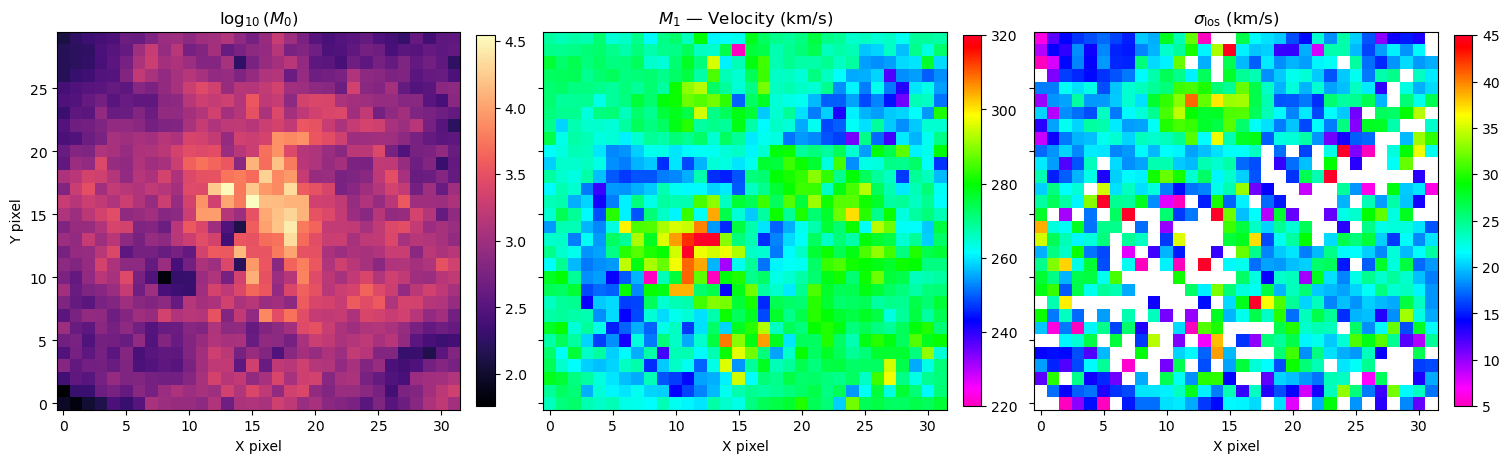

In [13]:
# ============================================================
# USER INPUTS
# ============================================================

# Velocity limits [km/s]
vmin_velocity = 220
vmax_velocity = 320

# Velocity dispersion limits [km/s]
vmin_sigma = 5
vmax_sigma = 45

# ============================================================
# PLOT MOMENT MAPS
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

maps = [
    np.log10(flux_map),
    velocity_map,
    sigma_map
]

titles = [
    r"$\log_{10}(M_0)$",
    r"$M_1$ — Velocity (km/s)",
    r"$\sigma_{\mathrm{los}}$ (km/s)"
]

#cmaps = ["magma", "RdBu_r", "viridis"]
cmaps = ["magma", "gist_rainbow_r", "gist_rainbow_r"]


# Color limits for each panel
limits = [
    (None, None),                     # Moment 0: automatic
    (vmin_velocity, vmax_velocity),   # Moment 1: 220–320 km/s
    (vmin_sigma, vmax_sigma)          # Sigma: 5–45 km/s
]

for ax, data, title, cmap, (vmin, vmax) in zip(
    axes, maps, titles, cmaps, limits
):

    im = ax.imshow(
        data,
        origin="lower",
        interpolation="nearest",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title)
    ax.set_xlabel("X pixel")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[0].set_ylabel("Y pixel")

plt.show()

In [14]:
# ============================================================
# DIAGNOSTIC: MOMENT 2
# ============================================================

m0 = moment0.to_value(u.nm)
m2 = moment2.to_value(u.nm**2)

print("Total spatial pixels:", m2.size)

print("Invalid spatial positions:",
      np.sum(~valid_spaxels))

print("NaN/Inf moment 2 in valid positions:",
      np.sum(valid_spaxels & ~np.isfinite(m2)))

print("Negative moment 2 in valid positions:",
      np.sum(valid_spaxels & np.isfinite(m2) & (m2 < 0)))

print("Nonpositive moment 0 in valid positions:",
      np.sum(valid_spaxels & np.isfinite(m0) & (m0 <= 0)))

print("NaN/Inf sigma in valid positions:",
      np.sum(valid_spaxels & ~np.isfinite(sigma_map)))

Total spatial pixels: 960
Invalid spatial positions: 0
NaN/Inf moment 2 in valid positions: 0
Negative moment 2 in valid positions: 167
Nonpositive moment 0 in valid positions: 0
NaN/Inf sigma in valid positions: 167


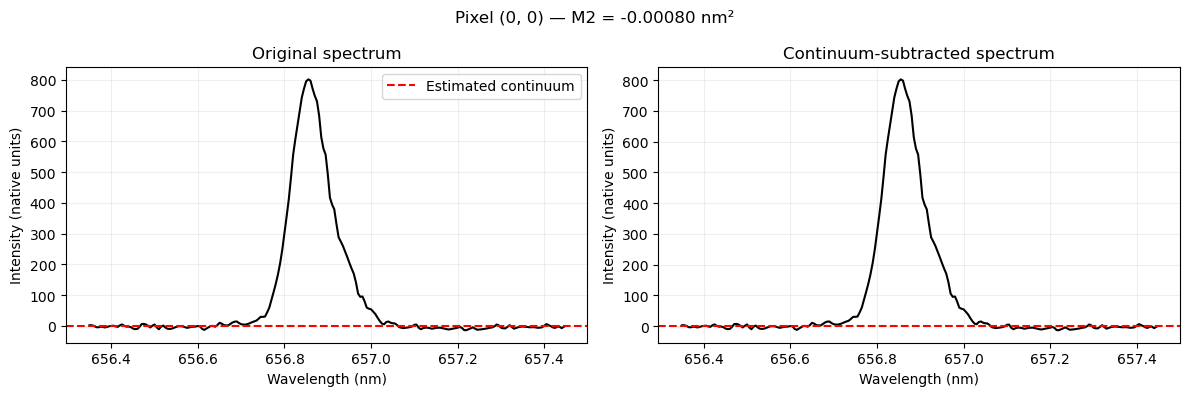

In [15]:
# Identify pixels with negative second moments
negative_pixels = np.argwhere(np.isfinite(m2) & (m2 < 0))

# Select the first affected pixel
y, x = negative_pixels[0]

# Extract the original and continuum-subtracted spectra
spec_raw = data_cube[:, y, x]
spec_cs = data_cs[:, y, x]

wavelength = cube.spectral_axis.to_value(u.nm)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4), sharex=True
)

# Original spectrum
axes[0].plot(wavelength, spec_raw, color="black")
axes[0].axhline(
    continuum[y, x],
    color="red",
    ls="--",
    label="Estimated continuum"
)
axes[0].set_title("Original spectrum")
axes[0].legend()

# Continuum-subtracted spectrum
axes[1].plot(wavelength, spec_cs, color="black")
axes[1].axhline(0, color="red", ls="--")
axes[1].set_title("Continuum-subtracted spectrum")

for ax in axes:
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Intensity (native units)")
    ax.grid(alpha=0.2)

fig.suptitle(
    f"Pixel ({x}, {y}) — M2 = {m2[y, x]:.5f} nm²"
)

plt.tight_layout()
plt.show()

In [16]:
import numpy as np
import astropy.units as u

# ============================================================
# 1. USER INPUTS
# ============================================================

blue_window = (656.4, 656.6)   # nm
red_window  = (657.2, 657.4)   # nm

# ============================================================
# 2. SPECTRAL AXIS
# ============================================================

wavelength = cube.spectral_axis.to_value(u.nm)

# ============================================================
# 3. ORIGINAL CONTINUUM: FULL SPECTRAL MEDIAN
# ============================================================

continuum_full = np.nanmedian(data_cube, axis=0)

# ============================================================
# 4. NEW CONTINUUM: SELECTED WINDOWS
# ============================================================

mask_blue = (
    (wavelength >= blue_window[0])
    & (wavelength <= blue_window[1])
)

mask_red = (
    (wavelength >= red_window[0])
    & (wavelength <= red_window[1])
)

mask_continuum = mask_blue | mask_red

continuum_windows = np.nanmedian(
    data_cube[mask_continuum, :, :],
    axis=0
)

# ============================================================
# 5. CONTINUUM-SUBTRACTED CUBES
# ============================================================

data_cs_full = data_cube - continuum_full[None, :, :]

data_cs_windows = data_cube - continuum_windows[None, :, :]

print("Channels used (full):", len(wavelength))
print("Channels used (windows):", mask_continuum.sum())

print("Continuum map shape:", continuum_windows.shape)

Channels used (full): 220
Channels used (windows): 81
Continuum map shape: (30, 32)


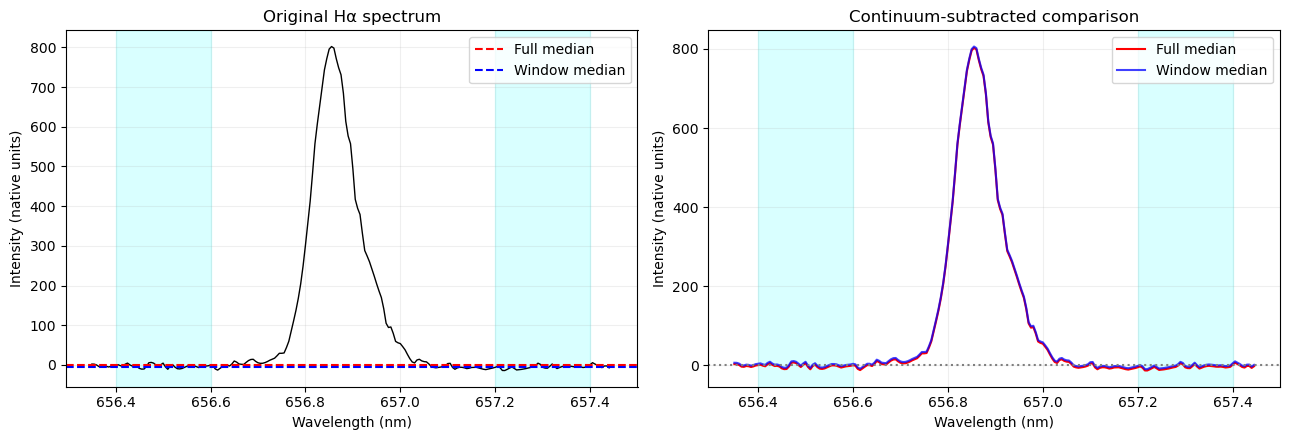

In [17]:
# Use previously selected spatial coordinates
# y, x = ...

spec_raw = data_cube[:, y, x]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# ============================================================
# ORIGINAL SPECTRUM
# ============================================================

axes[0].plot(wavelength, spec_raw, color="black", lw=1)

axes[0].axhline(
    continuum_full[y, x],
    color="red",
    ls="--",
    label="Full median"
)

axes[0].axhline(
    continuum_windows[y, x],
    color="blue",
    ls="--",
    label="Window median"
)

for ax in axes:
    ax.axvspan(*blue_window, color="cyan", alpha=0.15)
    ax.axvspan(*red_window, color="cyan", alpha=0.15)

axes[0].set_title("Original Hα spectrum")
axes[0].legend()

# ============================================================
# CONTINUUM-SUBTRACTED SPECTRA
# ============================================================

axes[1].plot(
    wavelength,
    data_cs_full[:, y, x],
    color="red",
    label="Full median"
)

axes[1].plot(
    wavelength,
    data_cs_windows[:, y, x],
    color="blue",
    alpha=0.75,
    label="Window median"
)

axes[1].axhline(0, color="gray", ls=":")
axes[1].set_title("Continuum-subtracted comparison")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Intensity (native units)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [18]:

# ============================================================
# 1. CONSTRUCT NEW CONTINUUM-SUBTRACTED CUBE
# ============================================================

cube_cs_windows = SpectralCube(
    data=data_cs_windows * u.one,
    wcs=wcs_fixed
)

mask = (
    np.isfinite(data_cs_windows)
    & valid_spaxels[None, :, :]
)

cube_cs_windows = cube_cs_windows.with_mask(mask)

# ============================================================
# 2. COMPUTE NEW MOMENTS
# ============================================================

moment0_windows = cube_cs_windows.moment0()
moment1_windows = cube_cs_windows.moment1()
moment2_windows = cube_cs_windows.moment2()

# ============================================================
# 3. COMPARE RESULTS
# ============================================================

m2_full = moment2.to_value(u.nm**2)
m2_windows = moment2_windows.to_value(u.nm**2)

print("FULL MEDIAN")
print("Negative M2:",
      np.sum(np.isfinite(m2_full) & (m2_full < 0)))

print("\nWINDOW MEDIAN")
print("Negative M2:",
      np.sum(np.isfinite(m2_windows) & (m2_windows < 0)))

print("\nNon-finite M2 (windows):",
      np.sum(~np.isfinite(m2_windows)))

FULL MEDIAN
Negative M2: 167

WINDOW MEDIAN
Negative M2: 0

Non-finite M2 (windows): 0


In [19]:
continuum_blue = np.nanmedian(
    data_cube[mask_blue, :, :],
    axis=0
)

continuum_red = np.nanmedian(
    data_cube[mask_red, :, :],
    axis=0
)

delta_continuum = continuum_red - continuum_blue

print("Median red-blue continuum difference:",
      np.nanmedian(delta_continuum))

Median red-blue continuum difference: 0.8081988096237183


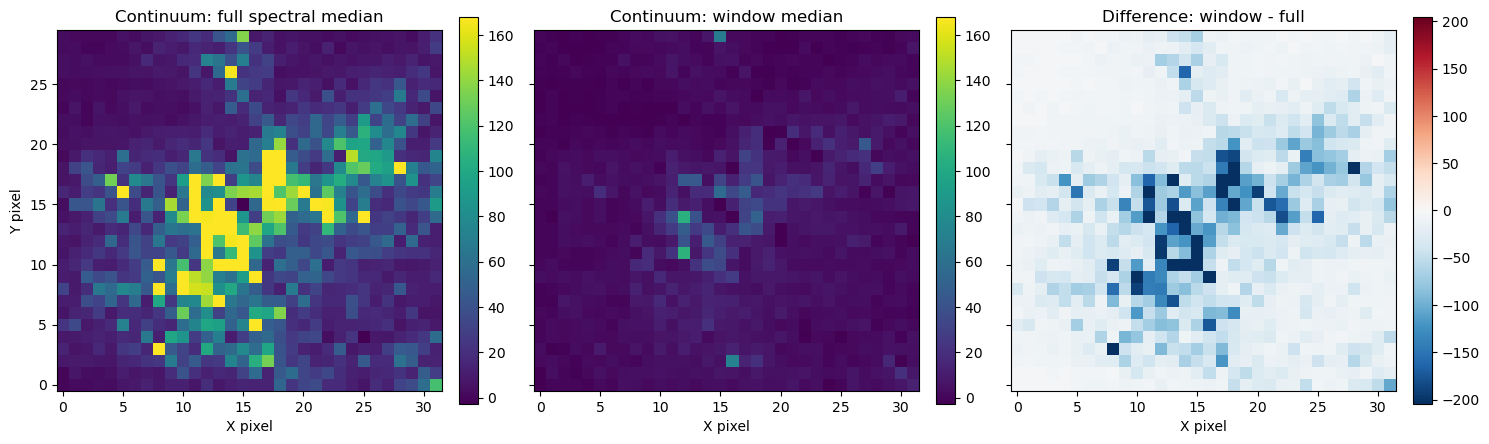

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# CONTINUUM COMPARISON
# ------------------------------------------------------------

cont_diff = continuum_windows - continuum_full

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)

maps = [
    continuum_full,
    continuum_windows,
    cont_diff
]

titles = [
    "Continuum: full spectral median",
    "Continuum: window median",
    "Difference: window - full"
]

cmaps = ["viridis", "viridis", "RdBu_r"]

# Robust limits for the first two panels
cont_all = np.concatenate([
    continuum_full[np.isfinite(continuum_full)].ravel(),
    continuum_windows[np.isfinite(continuum_windows)].ravel()
])

vmin_cont = np.nanpercentile(cont_all, 2)
vmax_cont = np.nanpercentile(cont_all, 98)

# Symmetric limits for the difference
diff_abs = np.nanpercentile(np.abs(cont_diff[np.isfinite(cont_diff)]), 98)

limits = [
    (vmin_cont, vmax_cont),
    (vmin_cont, vmax_cont),
    (-diff_abs, diff_abs)
]

for ax, data, title, cmap, (vmin, vmax) in zip(axes, maps, titles, cmaps, limits):
    im = ax.imshow(
        data,
        origin="lower",
        interpolation="nearest",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )
    ax.set_title(title)
    ax.set_xlabel("X pixel")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[0].set_ylabel("Y pixel")
plt.tight_layout()
plt.show()

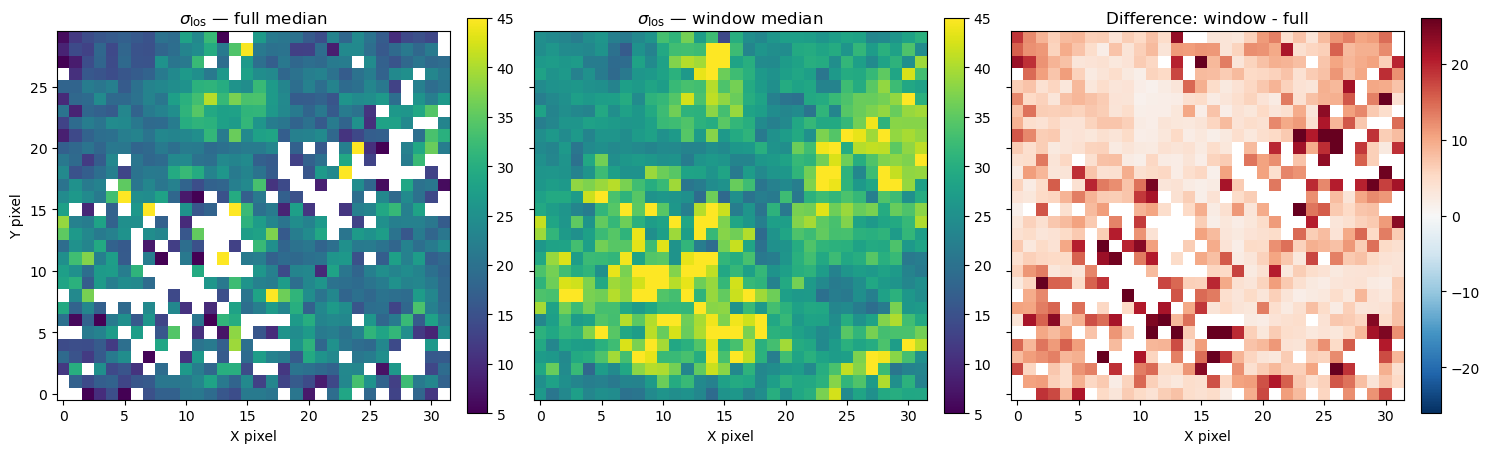

In [21]:
import numpy as np
import astropy.units as u
from astropy.constants import c
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# SIGMA MAPS FROM MOMENT 2
# ------------------------------------------------------------

# H-alpha rest wavelength in air
lambda0 = 656.279 * u.nm

m2_full = moment2.to_value(u.nm**2)
m2_windows = moment2_windows.to_value(u.nm**2)

# Convert to sigma [km/s]
sigma_map_full = np.full_like(m2_full, np.nan, dtype=float)
sigma_map_windows = np.full_like(m2_windows, np.nan, dtype=float)

mask_full = np.isfinite(m2_full) & (m2_full >= 0)
mask_windows = np.isfinite(m2_windows) & (m2_windows >= 0)

sigma_map_full[mask_full] = (
    c * np.sqrt(m2_full[mask_full]) * u.nm / lambda0
).to_value(u.km / u.s)

sigma_map_windows[mask_windows] = (
    c * np.sqrt(m2_windows[mask_windows]) * u.nm / lambda0
).to_value(u.km / u.s)

sigma_diff = sigma_map_windows - sigma_map_full

# ------------------------------------------------------------
# USER INPUTS FOR DISPLAY
# ------------------------------------------------------------

vmin_sigma = 5
vmax_sigma = 45

# For difference map
diff_abs = np.nanpercentile(
    np.abs(sigma_diff[np.isfinite(sigma_diff)]), 98
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)

maps = [
    sigma_map_full,
    sigma_map_windows,
    sigma_diff
]

titles = [
    r"$\sigma_{\mathrm{los}}$ — full median",
    r"$\sigma_{\mathrm{los}}$ — window median",
    r"Difference: window - full"
]

cmaps = ["viridis", "viridis", "RdBu_r"]

limits = [
    (vmin_sigma, vmax_sigma),
    (vmin_sigma, vmax_sigma),
    (-diff_abs, diff_abs)
]

for ax, data, title, cmap, (vmin, vmax) in zip(axes, maps, titles, cmaps, limits):
    im = ax.imshow(
        data,
        origin="lower",
        interpolation="nearest",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )
    ax.set_title(title)
    ax.set_xlabel("X pixel")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[0].set_ylabel("Y pixel")
plt.tight_layout()
plt.show()

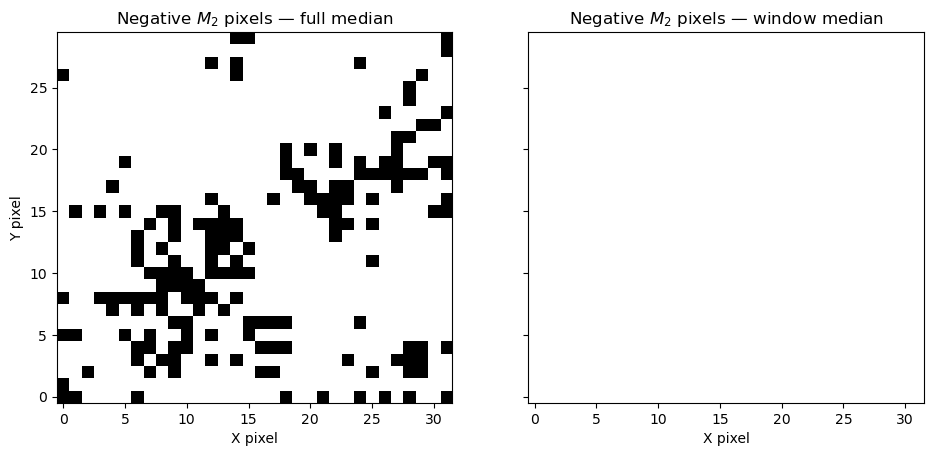

In [22]:
neg_full = np.isfinite(m2_full) & (m2_full < 0)
neg_windows = np.isfinite(m2_windows) & (m2_windows < 0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)

im0 = axes[0].imshow(neg_full.astype(int), origin="lower", cmap="gray_r", interpolation="nearest")
axes[0].set_title("Negative $M_2$ pixels — full median")
axes[0].set_xlabel("X pixel")
axes[0].set_ylabel("Y pixel")

im1 = axes[1].imshow(neg_windows.astype(int), origin="lower", cmap="gray_r", interpolation="nearest")
axes[1].set_title("Negative $M_2$ pixels — window median")
axes[1].set_xlabel("X pixel")

plt.tight_layout()
plt.show()

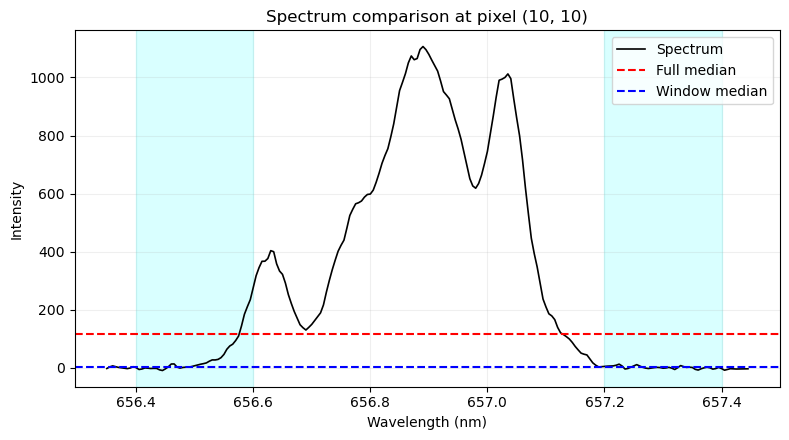

In [23]:
import matplotlib.pyplot as plt

# Example: choose one pixel
# Replace x0, y0 with your desired coordinates
x0, y0 = 10, 10

spec = data_cube[:, y0, x0]

plt.figure(figsize=(8, 4.5))
plt.plot(wavelength, spec, color="black", lw=1.2, label="Spectrum")

plt.axhline(continuum_full[y0, x0], color="red", ls="--", label="Full median")
plt.axhline(continuum_windows[y0, x0], color="blue", ls="--", label="Window median")

plt.axvspan(656.4, 656.6, color="cyan", alpha=0.15)
plt.axvspan(657.2, 657.4, color="cyan", alpha=0.15)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Intensity")
plt.title(f"Spectrum comparison at pixel ({x0}, {y0})")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

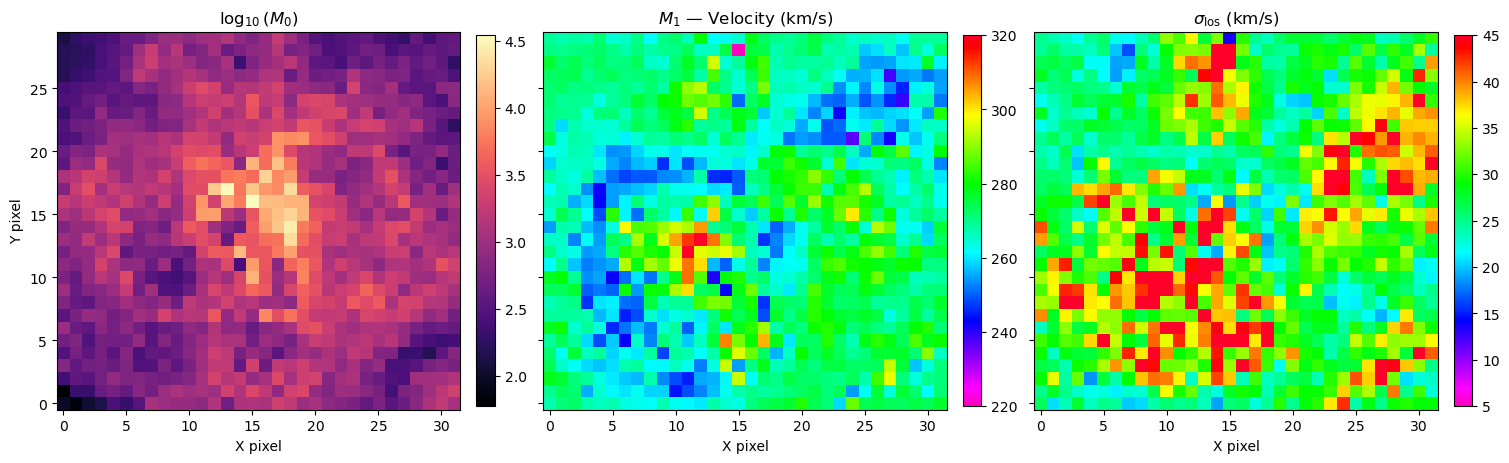

In [24]:
# ============================================================
# 1. USER INPUTS
# ============================================================

# H-alpha rest wavelength (air)
lambda0 = 656.279 * u.nm

# Velocity limits [km/s]
vmin_velocity = 220
vmax_velocity = 320

# Velocity dispersion limits [km/s]
vmin_sigma = 5
vmax_sigma = 45

# ============================================================
# 2. COMPUTE MAPS USING WINDOW CONTINUUM
# ============================================================

# Moment 0: Integrated intensity
flux_map = moment0_windows.to_value(u.nm)

# Moment 1: Radial velocity [km/s]
velocity_map = (
    c * (moment1_windows.to(u.nm) / lambda0 - 1)
).to_value(u.km / u.s)

# Moment 2: Velocity dispersion [km/s]
m2 = moment2_windows.to_value(u.nm**2)

sigma_map = np.full_like(m2, np.nan, dtype=float)

valid_m2 = np.isfinite(m2) & (m2 >= 0)

sigma_map[valid_m2] = (
    c * (np.sqrt(m2[valid_m2]) * u.nm) / lambda0
).to_value(u.km / u.s)

# Mask invalid integrated intensities
valid_flux = np.isfinite(flux_map) & (flux_map > 0)

flux_map = np.where(valid_flux, flux_map, np.nan)
velocity_map = np.where(valid_flux, velocity_map, np.nan)
sigma_map = np.where(valid_flux, sigma_map, np.nan)

# ============================================================
# 3. PLOT MOMENT MAPS
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

maps = [
    np.log10(flux_map),
    velocity_map,
    sigma_map
]

titles = [
    r"$\log_{10}(M_0)$",
    r"$M_1$ — Velocity (km/s)",
    r"$\sigma_{\mathrm{los}}$ (km/s)"
]

cmaps = ["magma", "gist_rainbow_r", "gist_rainbow_r"]

# Color limits for each panel
limits = [
    (None, None),                     # Moment 0: automatic
    (vmin_velocity, vmax_velocity),   # Moment 1: manual
    (vmin_sigma, vmax_sigma)          # Sigma: manual
]

for ax, data, title, cmap, (vmin, vmax) in zip(
    axes, maps, titles, cmaps, limits
):

    im = ax.imshow(
        data,
        origin="lower",
        interpolation="nearest",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title)
    ax.set_xlabel("X pixel")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[0].set_ylabel("Y pixel")

plt.show()

In [25]:
sigma = np.sqrt(sigma_map**2-7.8**2-9.1**2-10.2533)
#sigma = np.sqrt(sigma_map**2-7.8**2-9.1**2)

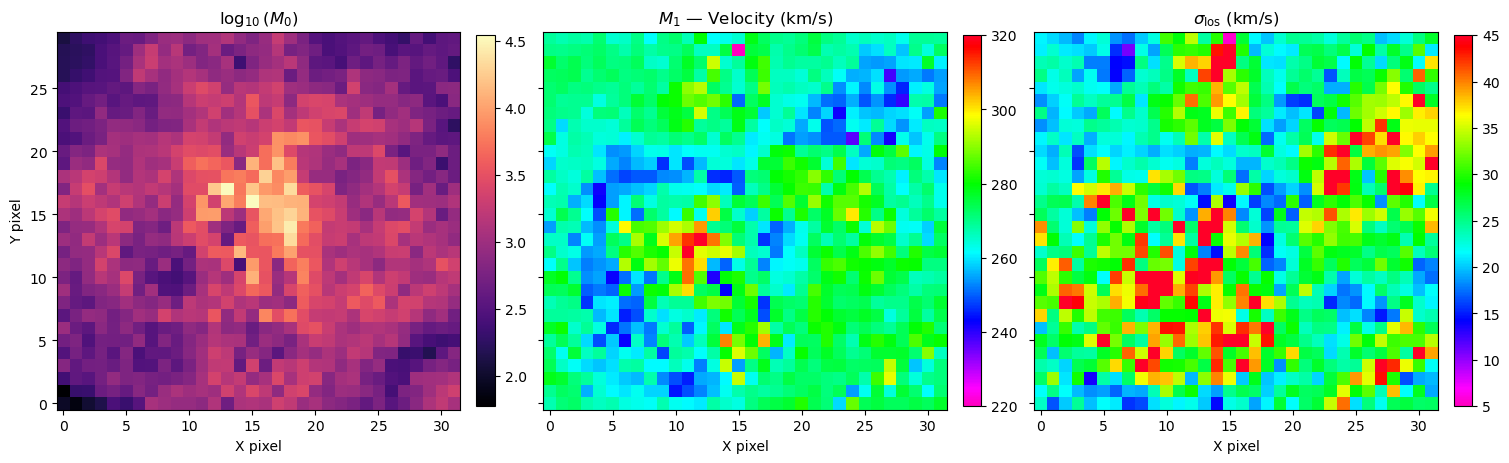

In [26]:
# ============================================================
# 1. USER INPUTS
# ============================================================

# H-alpha rest wavelength (air)
lambda0 = 656.279 * u.nm

# Velocity limits [km/s]
vmin_velocity = 220
vmax_velocity = 320

# Velocity dispersion limits [km/s]
vmin_sigma = 5
vmax_sigma = 45

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

maps = [
    np.log10(flux_map),
    velocity_map,
    sigma
]

titles = [
    r"$\log_{10}(M_0)$",
    r"$M_1$ — Velocity (km/s)",
    r"$\sigma_{\mathrm{los}}$ (km/s)"
]

cmaps = ["magma", "gist_rainbow_r", "gist_rainbow_r"]

# Color limits for each panel
limits = [
    (None, None),                     # Moment 0: automatic
    (vmin_velocity, vmax_velocity),   # Moment 1: manual
    (vmin_sigma, vmax_sigma),           # Sigma: manual
]

for ax, data, title, cmap, (vmin, vmax) in zip(
    axes, maps, titles, cmaps, limits
):

    im = ax.imshow(
        data,
        origin="lower",
        interpolation="nearest",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title)
    ax.set_xlabel("X pixel")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[0].set_ylabel("Y pixel")

plt.show()

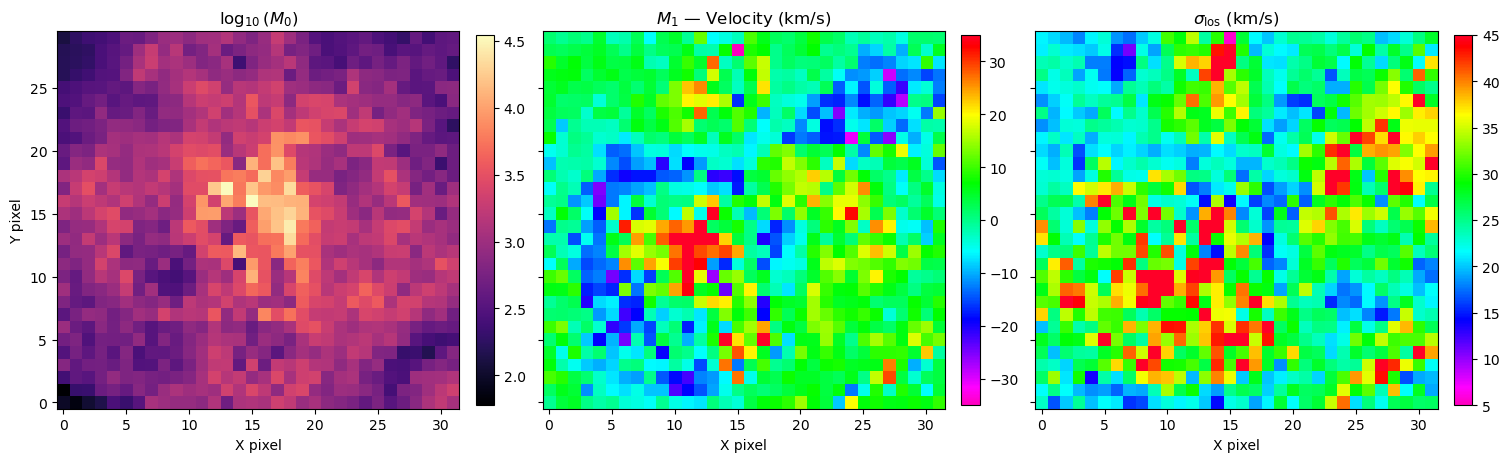

In [27]:
# ============================================================
# 1. USER INPUTS
# ============================================================

# H-alpha rest wavelength (air)
lambda0 = 656.279 * u.nm

# Velocity limits [km/s]
vmin_velocity = -35
vmax_velocity = 35

# Velocity dispersion limits [km/s]
vmin_sigma = 5
vmax_sigma = 45


fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

maps = [
    np.log10(flux_map),
    velocity_map-267.4,
    sigma
]

titles = [
    r"$\log_{10}(M_0)$",
    r"$M_1$ — Velocity (km/s)",
    r"$\sigma_{\mathrm{los}}$ (km/s)"
]

cmaps = ["magma", "gist_rainbow_r", "gist_rainbow_r"]

# Color limits for each panel
limits = [
    (None, None),                     # Moment 0: automatic
    (vmin_velocity, vmax_velocity),   # Moment 1: manual
    (vmin_sigma, vmax_sigma),           # Sigma: manual
]

for ax, data, title, cmap, (vmin, vmax) in zip(
    axes, maps, titles, cmaps, limits
):

    im = ax.imshow(
        data,
        origin="lower",
        interpolation="nearest",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title)
    ax.set_xlabel("X pixel")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[0].set_ylabel("Y pixel")

plt.show()

In [29]:
import numpy as np
import astropy.units as u
from astropy.io import fits
from pathlib import Path

# ============================================================
# 1. USER INPUTS
# ============================================================

output_dir = Path("results_moments")

output_dir.mkdir(parents=True, exist_ok=True)

prefix = "FLAMES_30Dor_Halpha_regular"

# ============================================================
# 2. SPATIAL WCS HEADER
# ============================================================

# Extract only the celestial WCS (RA and Dec)
header_2d = wcs_fixed.celestial.to_header(relax=True)

# Add information about the continuum subtraction
header_2d["CONTMETH"] = ("MED2WIN", "Two-window median continuum")
header_2d["CONT1LO"] = (656.4, "Blue window start [nm]")
header_2d["CONT1HI"] = (656.6, "Blue window end [nm]")
header_2d["CONT2LO"] = (657.2, "Red window start [nm]")
header_2d["CONT2HI"] = (657.4, "Red window end [nm]")

# Velocity convention and rest wavelength
header_2d["RESTWAV"] = (
    lambda0.to_value(u.m),
    "Assumed Halpha air rest wavelength [m]"
)

header_2d["VELCONV"] = ("OPTICAL", "Optical Doppler convention")
header_2d["VELFRAME"] = ("UNKNOWN", "Velocity reference frame unverified")

header_2d.add_history(
    "Moments computed after two-window median continuum subtraction."
)

header_2d.add_history(
    "Velocity dispersion derived from sqrt(second central moment)."
)

# ============================================================
# 3. DEFINE MAPS TO EXPORT
# ============================================================

products = {
    "M0": {
        "data": flux_map,
        "description": "Integrated Halpha intensity",
        "unit": None
    },
    "VMEAN": {
        "data": velocity_map,
        "description": "Intensity-weighted velocity",
        "unit": "km/s"
    },
    "SIGMA": {
        "data": sigma,
        "description": "Observed velocity dispersion",
        "unit": "km/s"
    }
}

# ============================================================
# 4. EXPORT FITS FILES
# ============================================================

for name, product in products.items():

    header_out = header_2d.copy()

    header_out["MAPTYPE"] = name
    header_out["MAPDESC"] = product["description"]

    if product["unit"] is not None:
        header_out["BUNIT"] = product["unit"]
    else:
        # Original FITS cube has no specified intensity unit
        header_out["INTUNIT"] = ("UNKNOWN", "Original intensity unit")
        header_out["M0UNIT"] = ("native * nm", "Integrated intensity units")

    data_out = np.asarray(
        product["data"],
        dtype=np.float32
    )

    filename = output_dir / f"{prefix}_{name}_windows.fits"

    fits.PrimaryHDU(
        data=data_out,
        header=header_out
    ).writeto(filename, overwrite=True)

    print(f"Saved: {filename}")

print("\nAll moment maps exported.")

Saved: results_moments\FLAMES_30Dor_Halpha_regular_M0_windows.fits
Saved: results_moments\FLAMES_30Dor_Halpha_regular_VMEAN_windows.fits
Saved: results_moments\FLAMES_30Dor_Halpha_regular_SIGMA_windows.fits

All moment maps exported.


In [30]:
moment1_windows

<Projection [[6.56863372e-07, 6.56873167e-07, 6.56875676e-07,
              6.56864863e-07, 6.56861081e-07, 6.56863401e-07,
              6.56855895e-07, 6.56854200e-07, 6.56852179e-07,
              6.56863541e-07, 6.56853778e-07, 6.56850467e-07,
              6.56848376e-07, 6.56865675e-07, 6.56859319e-07,
              6.56855898e-07, 6.56871710e-07, 6.56878467e-07,
              6.56881071e-07, 6.56884379e-07, 6.56896745e-07,
              6.56879317e-07, 6.56873299e-07, 6.56845504e-07,
              6.56908015e-07, 6.56878389e-07, 6.56881194e-07,
              6.56877271e-07, 6.56877671e-07, 6.56880593e-07,
              6.56877710e-07, 6.56884832e-07],
             [6.56868792e-07, 6.56876615e-07, 6.56873493e-07,
              6.56839218e-07, 6.56858162e-07, 6.56851109e-07,
              6.56847629e-07, 6.56853702e-07, 6.56844812e-07,
              6.56844936e-07, 6.56814243e-07, 6.56823293e-07,
              6.56832368e-07, 6.56841095e-07, 6.56853498e-07,
              6.5686485

In [31]:
vv = moment1_windows.value
sb = moment0_windows.value
ss = moment2_windows.value

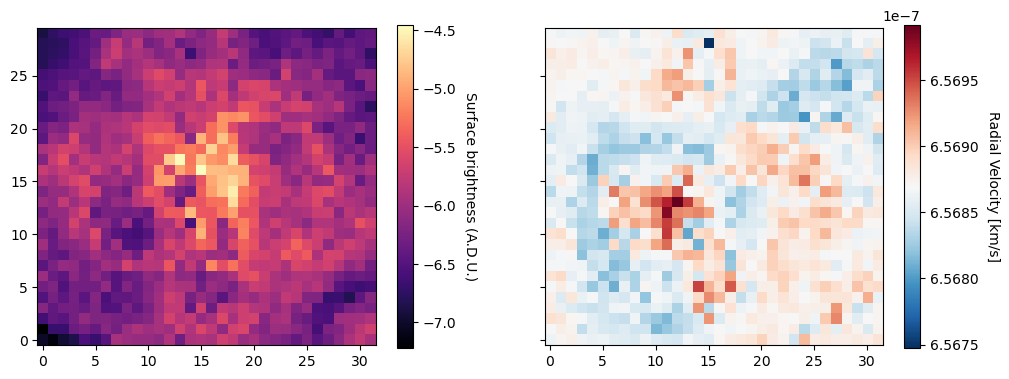

In [32]:
import matplotlib.pyplot as plt

fig, (axx, ax) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(12, 6),
)
imshow_kwds = dict(origin="lower", cmap="RdBu_r")
imshow_kwds2 = dict(origin="lower", cmap="magma")
im = ax.imshow(vv,**imshow_kwds)
#im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[ax], shrink=0.7)
cbar.set_label("Radial Velocity [km/s]", rotation=270, labelpad=15)
im = axx.imshow(np.log10(sb), **imshow_kwds2)
#im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[axx], shrink=0.7)
cbar.set_label("Surface brightness (A.D.U.)", rotation=270, labelpad=15)
#fig.suptitle(plot_label, y=0.8)

#plt.savefig('Imgs/' + name_id + '.jpg', bbox_inches='tight')

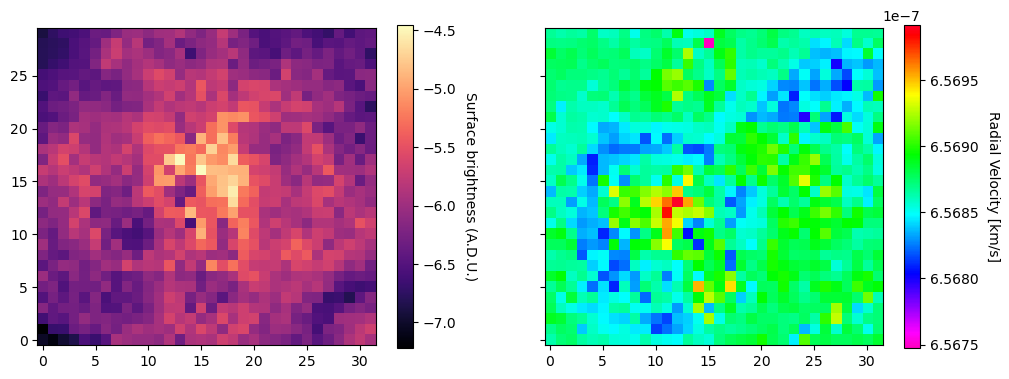

In [33]:
import matplotlib.pyplot as plt

fig, (axx, ax) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(12, 6),
)
imshow_kwds = dict(origin="lower", cmap="gist_rainbow_r")
imshow_kwds2 = dict(origin="lower", cmap="magma")
im = ax.imshow(vv,**imshow_kwds)
#im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[ax], shrink=0.7)
cbar.set_label("Radial Velocity [km/s]", rotation=270, labelpad=15)
im = axx.imshow(np.log10(sb), **imshow_kwds2)
#im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[axx], shrink=0.7)
cbar.set_label("Surface brightness (A.D.U.)", rotation=270, labelpad=15)
#fig.suptitle(plot_label, y=0.8)

#plt.savefig('Imgs/' + name_id + '.jpg', bbox_inches='tight')

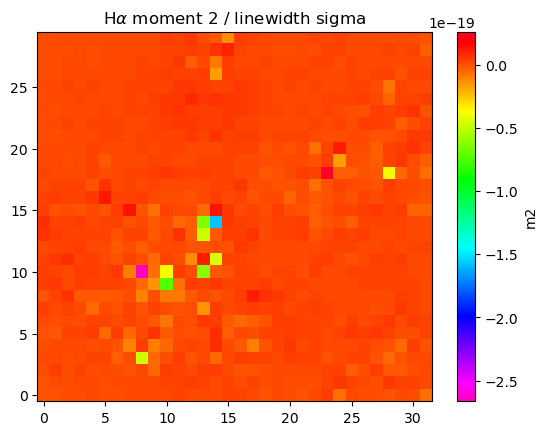

In [34]:

plt.imshow(moment2.value, origin="lower",  cmap="gist_rainbow_r")
plt.colorbar(label=str(moment2.unit))
plt.title(r"H$\alpha$ moment 2 / linewidth sigma")
plt.show()